## Day 1 – Step 1: Explore the data
Before combining, we open a few of the CSV files to understand their structure.

In [37]:
# Day 1 Step 1
import pandas as pd

# open one file and check the data
sample = pd.read_csv("../data/pis_1.csv")

print("shape:", sample.shape)
print(sample.dtypes)
sample.head(5)

shape: (12, 4)
category     object
month         int64
year          int64
clicks      float64
dtype: object


,category,month,year,clicks
0,men's low shoes,12,2021,82951.0
1,men's low shoes,2,2021,75533.0
2,men's low shoes,8,2021,86342.0
3,men's low shoes,10,2021,99433.0
4,men's low shoes,7,2021,81017.0


In [38]:
# Day 1 Step 2: Combine the files
# We read all 100 CSV files, stack them into one DataFrame and save the result.

dfs = [pd.read_csv(f"../data/pis_{i}.csv") for i in range(1, 101)]

# stack them below each other into one DataFrame
df = pd.concat(dfs, ignore_index=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   category  1200 non-null   object 
 1   month     1200 non-null   int64  
 2   year      1200 non-null   int64  
 3   clicks    1170 non-null   float64
dtypes: float64(1), int64(2), object(1)
memory usage: 37.6+ KB


In [39]:
# check that the combination is correct
print("rows:", len(df))                                                   
print("categories:", df["category"].nunique())                            
print("rows per category:", df.groupby("category").size().unique())       
print("duplicate rows:", df.duplicated(["category", "month", "year"]).sum())  

rows: 1200
categories: 100
rows per category: [12]
duplicate rows: 0


In [40]:
# save the combined data so we can reuse it later ()
df.to_csv("../data/combined_categories.csv", index=False)

In [41]:
import pandas as pd # As we have it in the first cell, we can skip this import if we are running the notebook in one go.
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../data/combined_categories.csv")

monthly = df.pivot(index="category", columns="month", values="clicks")
seasonal = monthly.div(monthly.mean(axis=1), axis=0)

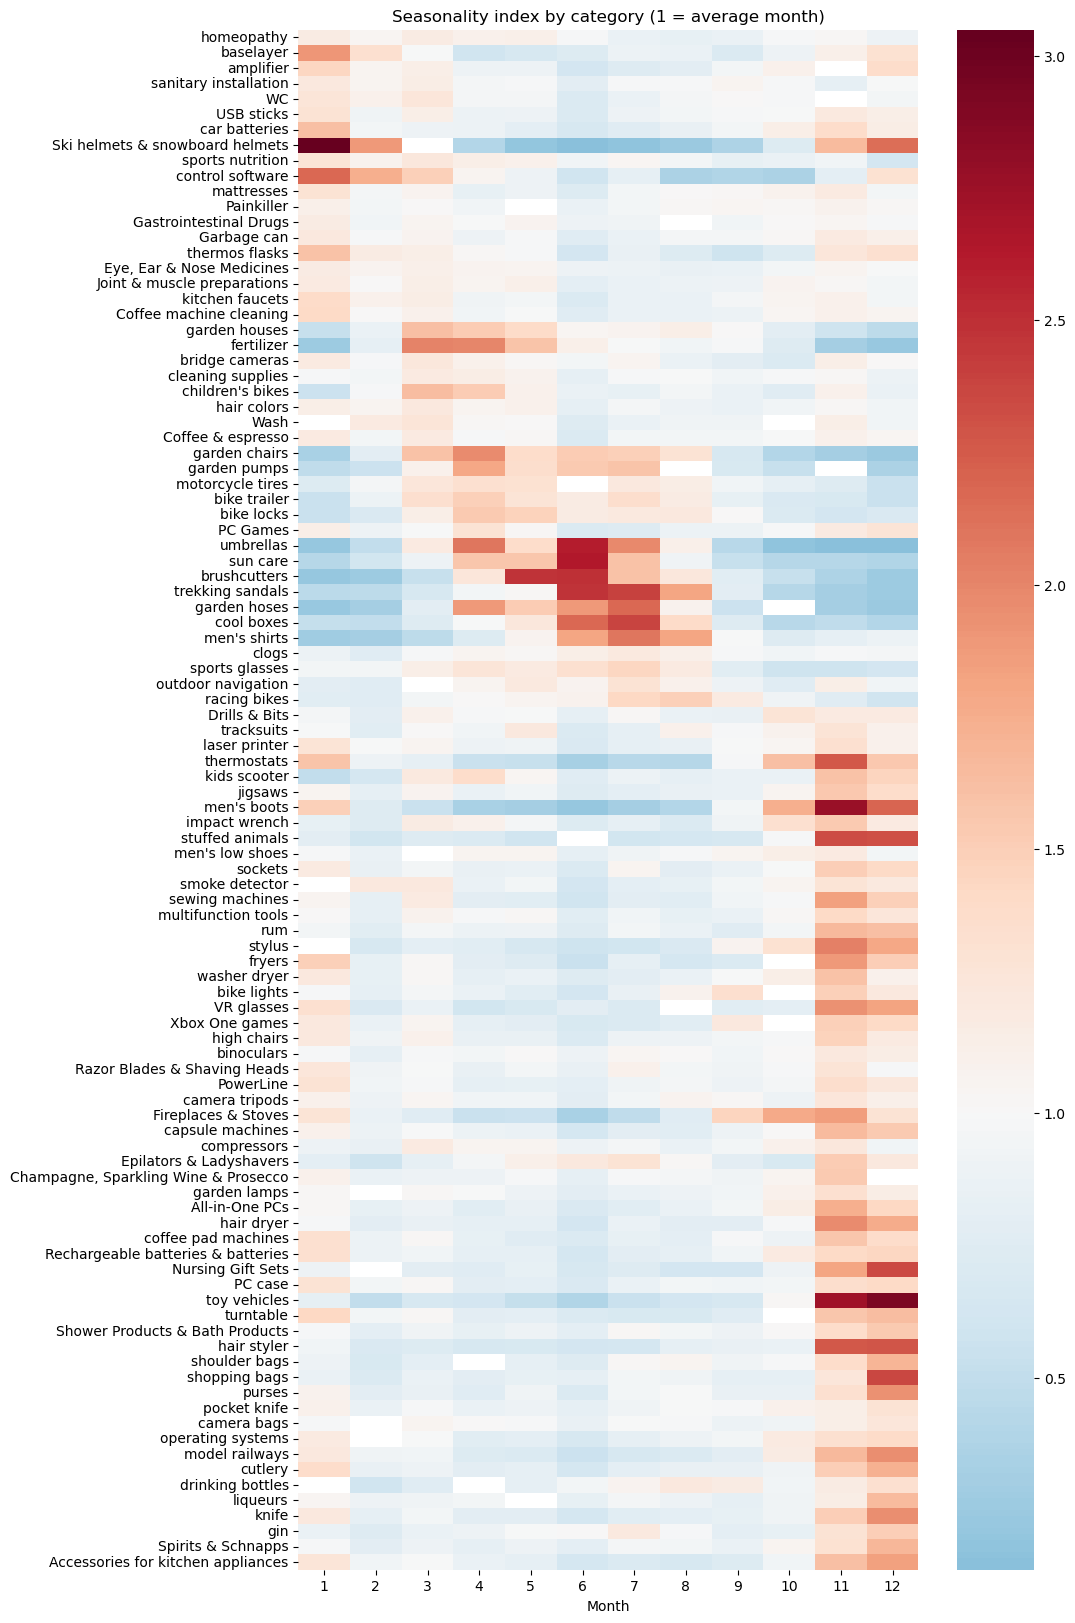

In [42]:
# Day1 Step 3: Visualize the seasonality index

order = seasonal.idxmax(axis=1).sort_values().index

plt.figure(figsize=(10, 20))
sns.heatmap(seasonal.loc[order], cmap="RdBu_r", center=1)
plt.title("Seasonality index by category (1 = average month)")
plt.xlabel("Month")
plt.ylabel("")
plt.show()

In [43]:
import plotly.express as px

# sort categories by their peak month (same order as the seaborn heatmap)
order = seasonal.idxmax(axis=1).sort_values().index

fig = px.imshow(seasonal.loc[order].round(2),
                color_continuous_scale="RdBu_r",
                color_continuous_midpoint=1,     # 1 = average month = white
                aspect="auto",
                labels=dict(x="Month", y="Category", color="Index"),
                title="Seasonality index by category (1 = average month)")
fig.update_layout(height=1800)
fig.show()

**What we see in the heatmap:**
- Many categories clearly peak in **summer** (e.g. sun care, umbrellas) and others in **winter** (e.g. ski helmets, men's boots).
- Some categories stay close to 1 all year (light colors) → **not seasonal**.
- The strongest seasonality: ski helmets (3.05× an average month), toy vehicles(December), men's boots, sun care.

## Day 1 – Step 4: Prepare a date column for time series plots

In [44]:
# build a real date from year + month (first day of the month)
df["date"] = pd.to_datetime(dict(year=df.year, month=df.month, day=1))

# sort by category and date (months were not sorted in the files)
df = df.sort_values(["category", "date"])

df.head(12)

,category,month,year,clicks,date
593,Accessories for kitchen appliances,1,2021,81676.0,2021-01-01
596,Accessories for kitchen appliances,2,2021,59529.0,2021-02-01
594,Accessories for kitchen appliances,3,2021,64537.0,2021-03-01
590,Accessories for kitchen appliances,4,2021,55455.0,2021-04-01
597,Accessories for kitchen appliances,5,2021,52882.0,2021-05-01
591,Accessories for kitchen appliances,6,2021,41856.0,2021-06-01
599,Accessories for kitchen appliances,7,2021,46075.0,2021-07-01
598,Accessories for kitchen appliances,8,2021,43049.0,2021-08-01
589,Accessories for kitchen appliances,9,2021,46719.0,2021-09-01
588,Accessories for kitchen appliances,10,2021,59479.0,2021-10-01


Note: we only have data for **one year (2021)**, so a per-year seasonality index would give exactly the same result as the `seasonal` table above. If more years are added later, the index should be calculated per year and then averaged.

<Axes: xlabel='month'>

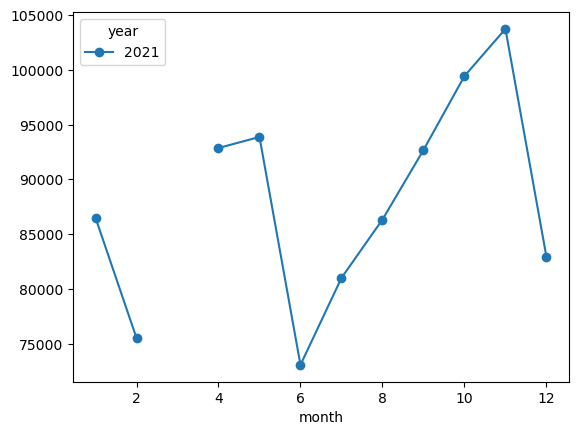

In [45]:
sub = df[df.category == "men's low shoes"]

sub.pivot(index="month", columns="year", values="clicks").plot(marker="o")

The gap between month 2 and 4 is because the clicks for **March are missing** in the data for this category.

In [46]:
import numpy as np

summary = pd.DataFrame({

    "peak_month": seasonal.idxmax(axis=1),

    "low_month": seasonal.idxmin(axis=1),

    "amplitude": seasonal.max(axis=1) - seasonal.min(axis=1),  # how strong

})

In [47]:


df.describe()



,month,year,clicks
count,1200.000000,1200.0,1170.000000
mean,6.500000,2021.0,67188.379487
std,3.453492,0.0,27991.394031
min,1.000000,2021.0,8408.000000
25%,3.750000,2021.0,49985.000000
50%,6.500000,2021.0,61564.000000
75%,9.250000,2021.0,78473.250000
max,12.000000,2021.0,230441.000000


In [48]:
# how many missing values per column?

df.isna().sum()

category     0
month        0
year         0
clicks      30
date         0
dtype: int64

In [49]:
# which categories have missing clicks, and how many?
missing = df[df["clicks"].isna()]

print("categories with missing clicks:", missing["category"].nunique())
missing.groupby("category").size().sort_values(ascending=False).head(10)

categories with missing clicks: 27


category
Wash                                    2
drinking bottles                        2
garden pumps                            2
Champagne, Sparkling Wine & Prosecco    1
garden lamps                            1
stylus                                  1
stuffed animals                         1
smoke detector                          1
shoulder bags                           1
outdoor navigation                      1
dtype: int64

In [50]:
# in which months are the missing values?
missing["month"].value_counts().sort_index()

1     4
2     4
3     3
4     2
5     2
6     2
8     3
10    6
11    3
12    1
Name: month, dtype: int64

In [51]:
# average clicks per month over all categories
clicks_by_month = df.groupby("month")["clicks"].mean().round(0)
clicks_by_month

month
1     71823.0
2     58077.0
3     68772.0
4     66378.0
5     65335.0
6     59255.0
7     65321.0
8     61079.0
9     58933.0
10    63419.0
11    86098.0
12    81729.0
Name: clicks, dtype: float64

<Axes: xlabel='clicks', ylabel='Count'>

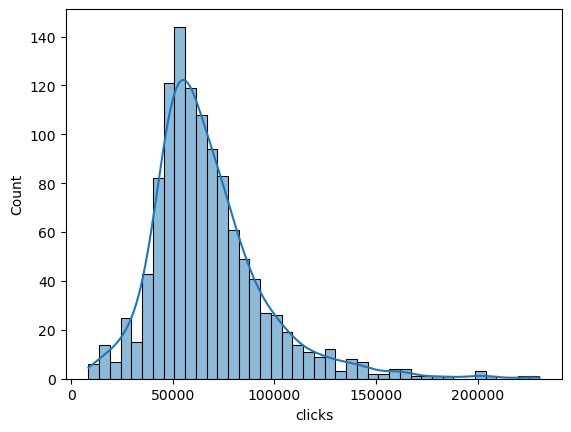

In [52]:
sns.histplot(data=df, x="clicks", kde=True)

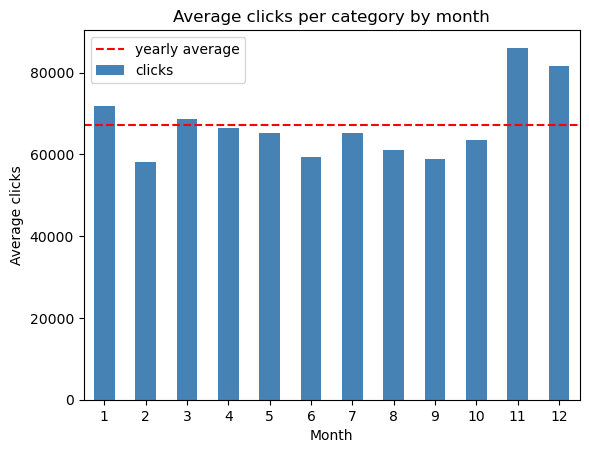

In [53]:
clicks_by_month.plot(kind="bar", color="steelblue")

plt.axhline(df["clicks"].mean(), color="red", linestyle="--", label="yearly average")
plt.title("Average clicks per category by month")
plt.xlabel("Month")
plt.ylabel("Average clicks")
plt.xticks(rotation=0)
plt.legend()
plt.show()

## Day 1 – Step 5: Analytical questions

Based on our exploration, we want to answer these questions:

1. **Which categories are clearly seasonal, and which are not?**
   → measured with the seasonality score (amplitude = peak index − low index).

2. **When does each category peak and when is it lowest?**
   → peak month and low month per category.

3. **Which months are most important for the whole shop?**
   → average clicks by month, and how many categories peak in each month.
   (First look: November and December are the busiest months.)

4. **Which categories have a similar seasonal pattern?**
   → e.g. "summer", "winter", "Christmas" and "flat" groups (to be done on Day 3 with clustering).

5. **Which seasonal categories are also big (many clicks)?**
   → these are the most important ones for promotion planning.

**Not possible with our data:**
- *"Are categories becoming more or less popular over time?"* → we only have **one year (2021)**, so we cannot measure trends or year-over-year change.

## Day 1 – Step 6: KPIs

We chose four KPIs per category: the **seasonality score** (highest minus lowest seasonality index), which shows how strongly seasonal a category is; the **peak month** and **low month**, which show when to promote a category and when demand is low; and the **average monthly clicks**, which shows how big a category is, so we can focus on categories that are both seasonal and big. A **year-over-year change** is not possible because we only have data for one year (2021).

## Day 2: Analyse, Visualise and Prepare the Application


###1. Continue the analysis
Use pandas to:

A- Prepare the data for analysis

B- Calculate your selected KPIs

C- Aggregate the data where necessary

D- Investigate your analytical questions

E- Identify interesting patterns

##A- Prepare the data for analysis


In [54]:
import pandas as pd
import numpy as np

# Load the combined data from Day 1
df = pd.read_csv("../data/combined_categories.csv")

# Quick checks: every category should have 12 months and no duplicates
print("Categories:", df["category"].nunique())
print("Rows per category:", df.groupby("category").size().unique())
print("Duplicates:", df.duplicated(["category", "year", "month"]).sum())
print("Missing clicks:", df["clicks"].isna().sum())

Categories: 100
Rows per category: [12]
Duplicates: 0
Missing clicks: 30


In [55]:
# Wide table: one row per category, one column per month
monthly_raw = df.pivot(index="category", columns="month", values="clicks")

def fill_circular(row):
    # Repeat the year 3 times so January and December have neighbours,
    # interpolate the gaps, then keep the middle copy
    tripled = pd.concat([row, row, row], ignore_index=True)
    filled = tripled.interpolate()
    return pd.Series(filled.iloc[12:24].values, index=row.index)

monthly = monthly_raw.apply(fill_circular, axis=1)

# Remember how many values were filled per category
filled_count = monthly_raw.isna().sum(axis=1)

print("Missing before:", monthly_raw.isna().sum().sum())
print("Missing after: ", monthly.isna().sum().sum())

Missing before: 30
Missing after:  0


In [56]:
# Validation: look at one category before and after filling
example = filled_count[filled_count > 0].index[0]
pd.DataFrame({"before": monthly_raw.loc[example],
              "after": monthly.loc[example].round(0)})

,before,after
month,,
1,59296.0,59296.0
2,45506.0,45506.0
3,48166.0,48166.0
4,47221.0,47221.0
5,52018.0,52018.0
6,43985.0,43985.0
7,51692.0,51692.0
8,51143.0,51143.0
9,48794.0,48794.0


###B- Calculate your selected KPIs


In [57]:
# Seasonality index: each month's clicks divided by the category's average month
# 1.0 = average month, 1.5 = 50% above average, 0.5 = half of average
seasonal = monthly.div(monthly.mean(axis=1), axis=0)

seasonal.round(2).head()

month,1,2,3,4,5,6,7,8,9,10,11,12
category,,,,,,,,,,,,
Accessories for kitchen appliances,1.27,0.92,1.00,0.86,0.82,0.65,0.71,0.67,0.72,0.92,1.61,1.84
All-in-One PCs,1.03,0.83,0.91,0.77,0.84,0.69,0.77,0.86,0.95,1.16,1.75,1.43
"Champagne, Sparkling Wine & Prosecco",1.09,0.83,0.88,0.86,0.95,0.81,0.95,0.94,0.89,1.02,1.49,1.29
Coffee & espresso,1.19,0.94,1.19,0.97,1.02,0.70,0.94,0.95,0.95,0.99,1.11,1.04
Coffee machine cleaning,1.40,1.00,1.11,0.93,0.99,0.76,0.86,0.85,0.88,1.04,1.11,1.06


In [58]:
# Every row should average to 1.0
seasonal.mean(axis=1).round(4).unique()

array([1.])

In [59]:
kpis = pd.DataFrame({
    # How strongly seasonal: highest index minus lowest index
    "seasonality_score": seasonal.max(axis=1) - seasonal.min(axis=1),
    # Month with the highest / lowest index
    "peak_month": seasonal.idxmax(axis=1),
    "low_month": seasonal.idxmin(axis=1),
    # Category size
    "avg_monthly_clicks": monthly.mean(axis=1),
    # Extra: how many times bigger the best month is than the worst
    "peak_vs_low": monthly.max(axis=1) / monthly.min(axis=1),
    # Extra: how many values were filled in step 1 (data quality flag)
    "filled_values": monthly_raw.isna().sum(axis=1),
}).round(2)

# Most seasonal categories first
kpis.sort_values("seasonality_score", ascending=False).head(10)

,seasonality_score,peak_month,low_month,avg_monthly_clicks,peak_vs_low,filled_values
category,,,,,,
Ski helmets & snowboard helmets,2.87,1,6,76446.67,21.43,1
men's boots,2.56,11,6,80801.58,13.46,0
toy vehicles,2.54,12,6,68628.00,7.74,0
umbrellas,2.47,6,12,61419.17,19.04,0
brushcutters,2.29,6,1,82421.33,12.11,0
sun care,2.25,6,12,68539.75,6.81,0
trekking sandals,2.23,6,12,57862.50,9.80,0
garden hoses,2.04,7,1,73414.38,9.60,1
cool boxes,1.98,7,12,62803.83,5.94,0


In [60]:
# Pick one category (change the name to test others)
cat = kpis["seasonality_score"].idxmax()
values = monthly.loc[cat]

# Recalculate by hand from the raw monthly clicks
manual_score = (values.max() - values.min()) / values.mean()

print("Category:", cat)
print("Score  -> manual:", round(manual_score, 2), "| table:", kpis.loc[cat, "seasonality_score"])
print("Peak   -> manual:", values.idxmax(),        "| table:", kpis.loc[cat, "peak_month"])
print("Low    -> manual:", values.idxmin(),        "| table:", kpis.loc[cat, "low_month"])

Category: Ski helmets & snowboard helmets
Score  -> manual: 2.87 | table: 2.87
Peak   -> manual: 1 | table: 1
Low    -> manual: 6 | table: 6


In [61]:
# Second measure: coefficient of variation
cv = monthly.std(axis=1) / monthly.mean(axis=1)

# Close to 1 = both measures rank the categories in the same order
print("Rank correlation score vs CV:", round(kpis["seasonality_score"].rank().corr(cv.rank()), 3))

Rank correlation score vs CV: 0.988


##C- Aggregate the data where necessary


In [62]:
# Total clicks per month across all categories
month_summary = pd.DataFrame({
    "total_clicks": monthly.sum(),
    "share_of_clicks_%": (monthly.sum() / monthly.sum().sum() * 100).round(1),
    # How many categories have their peak / lowest month here
    "categories_peaking": kpis["peak_month"].value_counts().reindex(range(1, 13), fill_value=0),
    "categories_lowest": kpis["low_month"].value_counts().reindex(range(1, 13), fill_value=0),
})

month_summary

,total_clicks,share_of_clicks_%,categories_peaking,categories_lowest
1,7173304.5,8.9,19,6
2,5824024.5,7.2,0,12
3,6898146.0,8.6,8,0
4,6595244.0,8.2,6,3
5,6505685.5,8.1,0,1
6,5924291.5,7.4,4,56
7,6532115.0,8.1,6,0
8,6140221.0,7.6,1,4
9,5893298.0,7.3,0,3
10,6410510.0,8.0,1,3


In [63]:
# Check: shares add up to 100%, and every category is counted once
print("Total share:", month_summary["share_of_clicks_%"].sum())
print("Peaks counted:", month_summary["categories_peaking"].sum())

Total share: 100.09999999999998
Peaks counted: 100


In [64]:
# Group categories by how strongly seasonal they are
# Thresholds are our choice: check kpis["seasonality_score"].describe() first
kpis["strength"] = pd.cut(kpis["seasonality_score"],
                          bins=[0, 0.5, 1.0, np.inf],
                          labels=["flat", "moderate", "strong"])

strength_summary = kpis.groupby("strength", observed=True).agg(
    categories=("seasonality_score", "size"),
    avg_score=("seasonality_score", "mean"),
    avg_monthly_clicks=("avg_monthly_clicks", "mean"),
).round(2)

strength_summary

,categories,avg_score,avg_monthly_clicks
strength,,,
flat,19,0.40,66014.08
moderate,44,0.75,66795.46
strong,37,1.64,68173.49


In [65]:
# Map each peak month to a season
season_map = {12: "winter", 1: "winter", 2: "winter",
              3: "spring", 4: "spring", 5: "spring",
              6: "summer", 7: "summer", 8: "summer",
              9: "autumn", 10: "autumn", 11: "autumn"}

kpis["peak_season"] = kpis["peak_month"].map(season_map)

# Flat categories have no real peak, so don't give them a season
kpis.loc[kpis["strength"] == "flat", "peak_season"] = "no clear season"

# How many categories per season and strength
pd.crosstab(kpis["peak_season"], kpis["strength"], margins=True)

strength,flat,moderate,strong,All
peak_season,,,,
autumn,0,18,11,29
no clear season,19,0,0,19
spring,0,6,5,11
summer,0,3,7,10
winter,0,17,14,31
All,19,44,37,100


In [66]:
# Which categories are in each season group (strongest first)
for season, group in kpis.sort_values("seasonality_score", ascending=False).groupby("peak_season"):
    print(f"{season} ({len(group)}):", ", ".join(group.index[:5]))

autumn (29): men's boots, thermostats, stuffed animals, Fireplaces & Stoves, stylus
no clear season (19): Drills & Bits, Coffee & espresso, pocket knife, camera tripods, Garbage can
spring (11): fertilizer, garden chairs, garden pumps, garden houses, children's bikes
summer (10): umbrellas, brushcutters, sun care, trekking sandals, garden hoses
winter (31): Ski helmets & snowboard helmets, toy vehicles, control software, Nursing Gift Sets, hair styler


In [67]:
# Split by median size and median score
size_median = kpis["avg_monthly_clicks"].median()
score_median = kpis["seasonality_score"].median()

is_big = kpis["avg_monthly_clicks"] >= size_median
is_seasonal = kpis["seasonality_score"] >= score_median

kpis["priority"] = np.select(
    [is_big & is_seasonal, ~is_big & is_seasonal, is_big & ~is_seasonal],
    ["1. big & seasonal", "2. small & seasonal", "3. big & steady"],
    default="4. small & steady",
)

kpis.groupby("priority").agg(
    categories=("seasonality_score", "size"),
    avg_monthly_clicks=("avg_monthly_clicks", "mean"),
    avg_score=("seasonality_score", "mean"),
).round(2)

,categories,avg_monthly_clicks,avg_score
priority,,,
1. big & seasonal,25,77078.34,1.59
2. small & seasonal,25,58042.38,1.32
3. big & steady,25,76095.35,0.59
4. small & steady,25,57411.41,0.55


Q3 – Which months matter most for the whole shop?
We summed the clicks of all 100 categories per month and counted how many categories peak or have their lowest month in each month.
A month can be important for two reasons: it has a large share of all clicks, or many categories peak in it.

## D- Investigate your analytical questions


In [68]:
# Q1/Q2: most and least seasonal categories with their peak and low months
cols = ["seasonality_score", "peak_month", "low_month", "peak_season"]
display(kpis.sort_values("seasonality_score", ascending=False)[cols].head(10))
display(kpis.sort_values("seasonality_score")[cols].head(10))

,seasonality_score,peak_month,low_month,peak_season
category,,,,
Ski helmets & snowboard helmets,2.87,1,6,winter
men's boots,2.56,11,6,autumn
toy vehicles,2.54,12,6,winter
umbrellas,2.47,6,12,summer
brushcutters,2.29,6,1,summer
sun care,2.25,6,12,summer
trekking sandals,2.23,6,12,summer
garden hoses,2.04,7,1,summer
cool boxes,1.98,7,12,summer


,seasonality_score,peak_month,low_month,peak_season
category,,,,
Painkiller,0.25,1,6,no clear season
Gastrointestinal Drugs,0.27,1,6,no clear season
"Eye, Ear & Nose Medicines",0.32,1,8,no clear season
homeopathy,0.34,1,8,no clear season
men's low shoes,0.35,11,6,no clear season
cleaning supplies,0.36,3,6,no clear season
Joint & muscle preparations,0.37,1,6,no clear season
hair colors,0.38,3,6,no clear season
binoculars,0.39,11,2,no clear season


In [69]:
# Q4: categories whose monthly pattern moves most like a given one
pattern_corr = seasonal.T.corr()

def most_similar(category, n=5):
    return pattern_corr[category].drop(category).sort_values(ascending=False).head(n).round(2)

most_similar("sun care")   # try other category names

category
umbrellas       0.96
brushcutters    0.90
garden hoses    0.90
garden pumps    0.87
cool boxes      0.85
Name: sun care, dtype: float64

In [70]:
# Q5: the biggest categories that are also seasonal
(kpis[kpis["priority"] == "1. big & seasonal"]
     .sort_values("avg_monthly_clicks", ascending=False)
     [["avg_monthly_clicks", "seasonality_score", "peak_month"]].head(10))

,avg_monthly_clicks,seasonality_score,peak_month
category,,,
capsule machines,87970.92,1.00,11
thermostats,87446.58,1.95,11
car batteries,86775.00,0.95,1
bike trailer,86118.25,0.95,4
fryers,86091.42,1.30,11
garden houses,84103.42,1.16,3
baselayer,82530.25,1.30,1
brushcutters,82421.33,2.29,6
men's boots,80801.58,2.56,11


## E- Identify interesting patterns

## Key findings
- **Q1:** Ski helmet, umbrella, sun creme categories are strongly seasonal, medicines are mostly flat.
- **Q2:** Most categories peak in winter/autumn; June is the lowest month for many.
- **Q3:** November and December have the highest share of clicks.
- **Q4:** Example: sun care moves together with ... (we can fill this)
- **Q5:** Top big & seasonal categories to plan campaigns for: ...(we can fill this)
- **Limitation:** only one year (2021), so no trends or year-over-year comparison.

### 2. Create visualisations with Plotly

Each chart answers one of our business questions.
Hover over the charts for details; click legend items to hide or show lines.

In [71]:
import plotly.express as px

# Month names make the charts easier to read
month_names = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
               7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"}

# Long table (one row per category and month) with filled clicks and the index
monthly_long = (monthly.stack().rename("clicks").to_frame()
                .join(seasonal.stack().rename("index"))
                .reset_index())
monthly_long["month_name"] = monthly_long["month"].map(month_names)
monthly_long = monthly_long.merge(kpis[["peak_season", "strength", "priority"]],
                                  left_on="category", right_index=True)
monthly_long.head()

,category,month,clicks,index,month_name,peak_season,strength,priority
0,Accessories for kitchen appliances,1,81676.0,1.265967,Jan,winter,strong,2. small & seasonal
1,Accessories for kitchen appliances,2,59529.0,0.922692,Feb,winter,strong,2. small & seasonal
2,Accessories for kitchen appliances,3,64537.0,1.000315,Mar,winter,strong,2. small & seasonal
3,Accessories for kitchen appliances,4,55455.0,0.859545,Apr,winter,strong,2. small & seasonal
4,Accessories for kitchen appliances,5,52882.0,0.819664,May,winter,strong,2. small & seasonal


#### 2.1 Clicks over time: compare selected categories
Change the list to explore any categories.

In [72]:
# Pick the categories you want to compare
selected = ["sun care", "umbrellas", "men's boots", "Painkiller"]

fig = px.line(monthly_long[monthly_long["category"].isin(selected)],
              x="month_name", y="clicks", color="category", markers=True,
              title="Monthly clicks in 2021 for selected categories",
              labels={"month_name": "Month", "clicks": "Clicks"})
fig.show()

#### 2.2 Monthly patterns for the whole shop (Q3)

In [73]:
# Share of all clicks per month; hover shows how many categories peak there
month_plot = month_summary.reset_index(names="month")
month_plot["month_name"] = month_plot["month"].map(month_names)

fig = px.bar(month_plot, x="month_name", y="share_of_clicks_%",
             hover_data=["categories_peaking", "categories_lowest"],
             title="Share of all clicks per month",
             labels={"month_name": "Month", "share_of_clicks_%": "Share of clicks (%)"})
fig.add_hline(y=100 / 12, line_dash="dash", annotation_text="average month")
fig.show()

#### 2.3 Peak and trough months (Q2)
In which months do categories have their best and their worst month?

In [74]:
# Count of categories per month: peak vs lowest month
peak_low = month_plot.melt(id_vars="month_name",
                           value_vars=["categories_peaking", "categories_lowest"],
                           var_name="type", value_name="categories")

fig = px.bar(peak_low, x="month_name", y="categories", color="type", barmode="group",
             title="Number of categories with their peak / lowest month",
             labels={"month_name": "Month", "categories": "Number of categories"})
fig.show()

#### 2.4 Most and least seasonal categories (Q1)

In [75]:
# Top 15 most seasonal categories, colored by peak season
top = kpis.sort_values("seasonality_score", ascending=False).head(15).reset_index()

fig = px.bar(top, x="seasonality_score", y="category", color="peak_season", orientation="h",
             hover_data=["peak_month", "low_month", "peak_vs_low"],
             title="15 most seasonal categories",
             labels={"seasonality_score": "Seasonality score", "category": ""})
fig.update_yaxes(categoryorder="total ascending")  # biggest bar on top
fig.show()

#### 2.5 Seasonal patterns: average shape of each season group (Q2 / Q4)
1.0 = an average month for the category.

In [76]:
# Average seasonality index per season group and month
season_shape = (monthly_long.groupby(["peak_season", "month", "month_name"], as_index=False)["index"]
                .mean())

fig = px.line(season_shape, x="month_name", y="index", color="peak_season", markers=True,
              title="Average seasonal pattern per group",
              labels={"month_name": "Month", "index": "Seasonality index", "peak_season": "Group"})
fig.add_hline(y=1, line_dash="dash")
fig.show()

#### 2.6 Similar categories (Q4)
Shows one category together with the categories whose pattern is most similar.

In [77]:
# Change the category name to explore others
base = "sun care"
group = [base] + most_similar(base, n=4).index.tolist()

fig = px.line(monthly_long[monthly_long["category"].isin(group)],
              x="month_name", y="index", color="category", markers=True,
              title=f"Categories with a pattern similar to '{base}'",
              labels={"month_name": "Month", "index": "Seasonality index"})
fig.show()

#### 2.7 Category comparison: size vs seasonality (Q5)
Top right = big and seasonal: the most important categories for campaign planning.

In [78]:
fig = px.scatter(kpis.reset_index(), x="seasonality_score", y="avg_monthly_clicks",
                 color="priority", hover_name="category",
                 hover_data=["peak_month", "low_month"],
                 title="Category size vs seasonality",
                 labels={"seasonality_score": "Seasonality score",
                         "avg_monthly_clicks": "Average monthly clicks"})
# Median lines that split the four priority groups
fig.add_vline(x=score_median, line_dash="dash")
fig.add_hline(y=size_median, line_dash="dash")
fig.show()

**What we see in the charts:** (fill in)

- 